# Brooklyn Nets 2026-27: season review, trade scenarios and a win forecast

**Question.** The Nets went 20-62 in 2025-26 and rebuilt in the summer (Randle in, Claxton out, a No. 6 pick). How good is this roster, what can trades and free agents change, and how many games should we expect them to win?

**What this notebook does**
1. Profiles the 2025-26 team against the league.
2. Builds a player report card (impact vs salary).
3. Builds and *backtests* a roster-based win forecast on 20 seasons of data, with the settings fixed before the 2026-27 forecast was made.
4. Forecasts 2026-27 for the roster as it stands.
5. Tests free agents and seven hypothetical trades against the 2026-27 salary-cap rules.

**Data (not redistributed here):** Basketball-Reference-style tables from the Kaggle dataset `sumitrodatta/nba-aba-baa-stats` (Advanced, Team Summaries) and a contracts table from `deocheng/nba-data-1946-2026`. Contracts were scraped on 18 June 2026, i.e. before free agency and before the 10 July four-team trade. The 2026-27 roster and salaries below were completed by hand from public reports (see README).

**Written on 21 October 2026, at the start of the season. No 2026-27 results were used.**

In [1]:
import pandas as pd, numpy as np, unicodedata, difflib
import matplotlib.pyplot as plt
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass

FOLDER = "/content/drive/MyDrive/nba_portfolio"   # change if your files live elsewhere
adv = pd.read_csv(f"{FOLDER}/Advanced.csv")
ts  = pd.read_csv(f"{FOLDER}/Team Summaries.csv")
con = pd.read_csv(f"{FOLDER}/public.player_contracts.csv")

ts = ts[ts.abbreviation.notna()].copy()
if "lg" in adv.columns:
    adv = adv[adv.lg == "NBA"]

def norm(s):
    # ascii letters only: makes names comparable across files with broken accents
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return "".join(ch for ch in s.lower() if ch.isalpha())

print(adv.season.max(), "latest stats season (2026 = 2025-26)")

Mounted at /content/drive
2026 latest stats season (2026 = 2025-26)


## 1. How good was Brooklyn in 2025-26?

Rank 1 = best in the league (for pace and three-point attempt rate, rank 1 = highest).

          metric    Nets  rank_of_30  league_avg
           o_rtg 108.700          30     115.780
           d_rtg 119.000          26     115.730
           n_rtg -10.300          29       0.050
            pace  97.100          25      99.353
          x3p_ar   0.455           6       0.415
      ts_percent   0.559          30       0.581
    e_fg_percent   0.520          30       0.546
     tov_percent  14.300          29      12.740
     orb_percent  23.600          24      26.003
     drb_percent  74.000          18      73.990
          ft_fga   0.212          14       0.207
opp_e_fg_percent   0.571          28       0.546
 opp_tov_percent  13.200          10      12.737
      opp_ft_fga   0.225          27       0.206


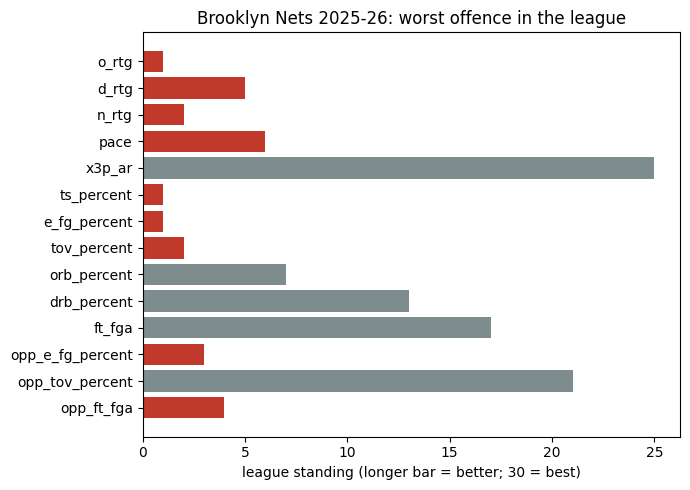

In [2]:
cur = ts[ts.season == 2026].set_index("abbreviation")
metrics = ["o_rtg", "d_rtg", "n_rtg", "pace", "x3p_ar", "ts_percent",
           "e_fg_percent", "tov_percent", "orb_percent", "drb_percent",
           "ft_fga", "opp_e_fg_percent", "opp_tov_percent", "opp_ft_fga"]
lower_better = {"d_rtg", "tov_percent", "opp_e_fg_percent", "opp_ft_fga"}
rows = []
for m in metrics:
    rk = cur[m].rank(ascending=(m in lower_better), method="min")
    rows.append((m, cur.loc["BRK", m], int(rk["BRK"]), round(cur[m].mean(), 3)))
prof = pd.DataFrame(rows, columns=["metric", "Nets", "rank_of_30", "league_avg"])
print(prof.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 5))
p = prof.iloc[::-1]
ax.barh(p.metric, 31 - p.rank_of_30, color=["#c0392b" if r >= 25 else "#7f8c8d" for r in p.rank_of_30])
ax.set_xlabel("league standing (longer bar = better; 30 = best)")
ax.set_title("Brooklyn Nets 2025-26: worst offence in the league")
plt.tight_layout(); plt.show()

The offence was last in the league (108.7 points per 100 possessions), driven by the worst shooting efficiency (true shooting 30th, effective FG% 30th) and 29th in turnovers, even though the team took the 6th-highest share of its shots from three. The defence was also poor (26th), mainly because opponents shot well (opponent effective FG% 28th) and got to the line.

## 2. Player report card (2025-26)

BPM is Box Plus/Minus (points per 100 possessions above an average player), VORP is value over a replacement player, WS/48 is win shares per 48 minutes. Small minute totals mean noisy numbers (for example Minott, +3.0 BPM in only 308 Nets minutes).

In [3]:
nets = adv[(adv.season == 2026) & adv.team.isin(["BRK", "BKN"])].copy()
nets["key"] = nets.player.map(norm)

cn = con[con.team_abbr.isin(["BRK", "BKN"])].copy()
cn["key"] = cn.player_name.map(norm)
cn_keys = list(cn.key)

def match_key(k):
    m = difflib.get_close_matches(k, cn_keys, n=1, cutoff=0.8)
    return m[0] if m else None

nets["ckey"] = nets.key.map(match_key)
nets = nets.merge(cn[["key", "salary_2025_26"]], left_on="ckey", right_on="key",
                  how="left", suffixes=("", "_c"))
nets["sal_m"] = nets.salary_2025_26 / 1e6
nets["vorp_per_m"] = nets.vorp / nets.sal_m

cols = ["player", "age", "pos", "mp", "usg_percent", "ts_percent",
        "ws_48", "bpm", "vorp", "sal_m", "vorp_per_m"]
card = nets.sort_values("mp", ascending=False)[cols].round(3)
print(card.to_string(index=False))
tot = nets.mp.sum()
print("\nminutes total:", tot, "| minute-weighted team BPM:", round((nets.bpm * nets.mp).sum() / tot, 2))

            player  age pos     mp  usg_percent  ts_percent  ws_48  bpm  vorp  sal_m  vorp_per_m
       Nic Claxton 26.0   C 1920.0         17.7       0.592  0.121  0.9   1.4 25.352       0.055
      Noah Clowney 21.0  PF 1780.0         20.4       0.554  0.029 -3.4  -0.6  3.399      -0.177
Michael Porter Jr. 27.0  SF 1689.0         30.5       0.595  0.083  3.0   2.1 38.333       0.055
      Terance Mann 29.0  SG 1529.0         13.5       0.564  0.056 -3.4  -0.6 15.500      -0.039
      Drake Powell 20.0  SG 1320.0         14.9       0.521 -0.003 -6.0  -1.3  3.372      -0.386
        Egor Dёmin 19.0  PG 1308.0         18.8       0.561  0.032 -1.6   0.1  6.889       0.015
   Ziaire Williams 24.0  SF 1281.0         18.9       0.579  0.059 -1.7   0.1  6.250       0.016
      Nolan Traoré 19.0  PG 1243.0         22.8       0.479 -0.063 -6.8  -1.5  3.812      -0.394
        Danny Wolf 21.0  PF 1187.0         20.6       0.521  0.032 -2.5  -0.2  2.801      -0.071
    Day'Ron Sharpe 24.0   C 11

**Reading it.** Porter Jr. (+3.0 BPM), Sharpe (+1.4, best WS/48) and the departed Claxton (+0.9) carried the team. The most expensive negative values were Mann ($15.5M through 2027-28, BPM -3.4) and the three 2025 first-round guards Traoré, Saraf and Powell (BPM between -6.0 and -7.3 over 900-1,300 minutes each). Rookie seasons like that are common for 19-20-year-olds, which is why the forecast below does not simply carry their numbers forward.

The minute-weighted BPM times five players on the court gives a team rating of about -11.8, close to the actual -10.3. So BPM is a reasonable building block for team strength.

## 3. A forecasting method, and how well it works

**Method.** For every player, take last season's BPM and shrink it toward a prior of -2.0 in proportion to how few minutes he played: `s = (BPM*MP + prior*K) / (MP + K)` with K = 500 minutes. A player with no NBA minutes (a rookie) gets the prior. Team rating = sum of `s` x (minutes per game / 48). Net rating is then converted to wins with a regression on all 82-game seasons since 2001.

**Fixed in advance:** K = 500 and prior = -2.0 are the settings used for every forecast below. Other K values are shown only to show how much it matters.

**Backtest.** For each season 2006-2026 (excluding 2020, 2021) predict every team's net rating from *last* season's player BPM and the *actual* current-season minutes, and compare with the real net rating. This tests the talent measure, not minute allocation.

In [4]:
K, PRIOR = 500, -2.0
is_total = adv.team.isin(["TOT"]) | adv.team.str.endswith("TM")
team_rows = adv[~is_total]
prev = adv.sort_values("mp").drop_duplicates(["season", "player_id"], keep="last")
seasons = [s for s in range(2006, 2027) if s not in (2020, 2021)]
actual = ts.set_index(["season", "abbreviation"]).n_rtg

def raw_team(S, k=K, prior=PRIOR, prior_young=None):
    c_ = team_rows[team_rows.season == S][["player_id", "team", "mp", "age"]]
    p_ = prev[prev.season == S - 1][["player_id", "bpm", "mp"]].rename(columns={"bpm": "pb", "mp": "pmp"})
    d = c_.merge(p_, on="player_id", how="left")
    d["pmp"] = d.pmp.fillna(0)
    d["pb"] = d.pb.fillna(0)
    pr = prior if prior_young is None else np.where(d.age <= 21, prior_young, prior)
    d["s"] = (d.pb * d.pmp + pr * k) / (d.pmp + k)
    d["w"] = d.s * d.mp
    return d.groupby("team").w.sum() / d.groupby("team").mp.sum() * 5

def evaluate(k=K, prior=PRIOR, prior_young=None):
    ps, ac = [], []
    for S in seasons:
        g = raw_team(S, k, prior, prior_young)
        g = g - g.mean()
        for team, v in g.items():
            if (S, team) in actual.index:
                ps.append(v); ac.append(actual[(S, team)])
    ps, ac = np.array(ps), np.array(ac)
    return round(np.corrcoef(ps, ac)[0, 1], 3), round(np.sqrt(np.mean((ps - ac) ** 2)), 2)

out = []
for k in [0, 250, 500, 1000, 2000]:
    r, e = evaluate(k)
    out.append(("shrink K=%d, prior -2.0" % k, r, e))
ps, ac = [], []
for S in seasons:
    for team in ts[ts.season == S].abbreviation:
        if (S - 1, team) in actual.index:
            ps.append(actual[(S - 1, team)]); ac.append(actual[(S, team)])
out.append(("naive: last season's net rating",
            round(np.corrcoef(ps, ac)[0, 1], 3),
            round(np.sqrt(np.mean((np.array(ps) - np.array(ac)) ** 2)), 2)))
print(pd.DataFrame(out, columns=["variant", "corr", "RMSE_net_rating"]).to_string(index=False))
print("\nprior -2/-3/-4 for players aged <=21 (RMSE):",
      {py: evaluate(prior_young=py)[1] for py in [-2.0, -3.0, -4.0]})

# conversion from net rating to wins, all 82-game seasons since 2001
ts["g"] = ts.w + ts.l
full = ts[(ts.g == 82) & (ts.season >= 2001)]
SLOPE, ICPT = np.polyfit(full.n_rtg, full.w, 1)
RESID_SD = float((full.w - (ICPT + SLOPE * full.n_rtg)).std())
RMSE_NET = evaluate()[1]
BAND = float(np.sqrt((RMSE_NET * SLOPE) ** 2 + RESID_SD ** 2))
OFFSET = float(np.mean([raw_team(S).mean() for S in seasons]))
print("\nwins = %.1f + %.2f x net rating (residual SD %.1f wins)" % (ICPT, SLOPE, RESID_SD))
print("forecast uncertainty (1 SD): about +-%.1f wins" % BAND)

g = raw_team(2026); g = g - g.mean()
print("Example: Nets 2025-26 predicted from 2024-25 data: %.1f, actual %.1f" % (g["BRK"], actual[(2026, "BRK")]))

                        variant  corr  RMSE_net_rating
         shrink K=0, prior -2.0 0.728             3.71
       shrink K=250, prior -2.0 0.787             3.18
       shrink K=500, prior -2.0 0.785             3.11
      shrink K=1000, prior -2.0 0.781             3.14
      shrink K=2000, prior -2.0 0.776             3.36
naive: last season's net rating 0.610             4.37

prior -2/-3/-4 for players aged <=21 (RMSE): {-2.0: np.float64(3.11), -3.0: np.float64(3.13), -4.0: np.float64(3.19)}

wins = 41.0 + 2.44 x net rating (residual SD 3.0 wins)
forecast uncertainty (1 SD): about +-8.2 wins
Example: Nets 2025-26 predicted from 2024-25 data: -5.4, actual -10.3


**Result.** Shrinking helps a lot (RMSE 3.7 with no shrinkage, 3.1 at K = 500) and the method beats the naive "repeat last year's rating" forecast (corr 0.79 vs 0.61, RMSE 3.1 vs 4.4). Converted to wins the typical error is about 8 games, so any single team forecast is a wide range, not a number.

The method *missed on Brooklyn itself* in 2025-26 (predicted -5.4, actual -10.3): a very young team underperformed its prior-year numbers. A lower prior for young players did not improve the backtest (RMSE 3.11 -> 3.13 for -3.0), so it stays a sensitivity case only.

## 4. Forecast for 2026-27 (roster as it stands)

**Roster and rotation.** The rotation order is the projection published by ClutchPoints, not ours: Brown Jr., Demin, Porter Jr., Randle, Sharpe start; Ellis, Wagner, Mann, Traoré, Clowney, Minott, Wolf, Powell follow. Minutes per game by rotation slot: 34-32-30-28-26-22-18-14-12-10-6-4-4 (sum 240). No injuries are modelled.

In [5]:
MIN = [34, 32, 30, 28, 26, 22, 18, 14, 12, 10, 6, 4, 4]
BASE = ["Mikel Brown Jr.", "Egor Demin", "Michael Porter Jr.", "Julius Randle",
        "Day'Ron Sharpe", "Keon Ellis", "Moritz Wagner", "Terance Mann",
        "Nolan Traore", "Noah Clowney", "Josh Minott", "Danny Wolf", "Drake Powell"]
AGE = {"Mikel Brown Jr.": 20, "Egor Demin": 20, "Nolan Traore": 20, "Drake Powell": 21,
       "Noah Clowney": 22, "Danny Wolf": 22}      # approximate; only used in the young-prior sensitivity

st = prev[prev.season == 2026].copy()
st["key"] = st.player.map(norm)
st_keys = list(st.key)

def find(name):
    k = norm(name)
    if k not in st_keys:
        m = difflib.get_close_matches(k, st_keys, n=1, cutoff=0.9)
        if not m:
            return None
        k = m[0]
    return st[st.key == k].iloc[0]

def forecast(order, merit=False, prior_young=None, verbose=False):
    rows = []
    for i, name in enumerate(order):
        r = find(name)
        bpm, mp = (0.0, 0.0) if r is None else (r.bpm, r.mp)
        pr = PRIOR
        if prior_young is not None and AGE.get(name, 99) <= 21:
            pr = prior_young
        s = (bpm * mp + pr * K) / (mp + K)
        rows.append((name, round(bpm, 1), mp, round(s, 2)))
    d = pd.DataFrame(rows, columns=["player", "bpm_2526", "mp_2526", "s"])
    if merit:
        slots = d.s.rank(ascending=False, method="first").astype(int) - 1
        d["min_pg"] = [MIN[j] if j < len(MIN) else 0 for j in slots]
    else:
        d["min_pg"] = [MIN[i] if i < len(MIN) else 0 for i in range(len(d))]
    net = (d.s * d.min_pg / 48).sum() - OFFSET
    wins = ICPT + SLOPE * net
    if verbose:
        print(d.to_string(index=False))
    return net, wins

def change(order, out=(), add=(), at=None):
    new = [p for p in order if p not in out]
    for j, p in enumerate(add):
        pos = at[j] if at is not None else len(new)
        new.insert(min(pos, len(new)), p)
    return new

net, base_w = forecast(BASE, verbose=True)
print("\nPRIMARY FORECAST: net rating %.1f, %.1f wins (+-%.1f, 1 SD)" % (net, base_w, BAND))
print("variant, minutes by our ranking:   %.1f wins" % forecast(BASE, merit=True)[1])
print("variant, prior -3.0 for age<=21:   %.1f wins" % forecast(BASE, prior_young=-3.0)[1])
print("market (Kalshi, 29 July):          26.2 wins")

            player  bpm_2526  mp_2526     s  min_pg
   Mikel Brown Jr.       0.0      0.0 -2.00      34
        Egor Demin      -1.6   1308.0 -1.71      32
Michael Porter Jr.       3.0   1689.0  1.86      30
     Julius Randle       1.5   2610.0  0.94      28
    Day'Ron Sharpe       1.4   1160.0  0.38      26
        Keon Ellis      -0.5   1478.0 -0.88      22
     Moritz Wagner      -2.2    427.0 -2.09      18
      Terance Mann      -3.4   1529.0 -3.06      14
      Nolan Traore      -6.8   1243.0 -5.42      12
      Noah Clowney      -3.4   1780.0 -3.09      10
       Josh Minott       2.5    834.0  0.81       6
        Danny Wolf      -2.5   1187.0 -2.35       4
      Drake Powell      -6.0   1320.0 -4.90       4

PRIMARY FORECAST: net rating -2.9, 33.8 wins (+-8.2, 1 SD)
variant, minutes by our ranking:   40.6 wins
variant, prior -3.0 for age<=21:   31.4 wins
market (Kalshi, 29 July):          26.2 wins


**Reading it.**
- **Primary forecast: 33.8 wins, give or take 8.** The prediction market sits at 26.2, 7.6 wins lower. The gap is inside our own error band, but the market knows things we do not (injuries: Traoré's knee, Wagner's ACL; Randle is 32; Porter's contract situation). We also over-predicted this franchise last year, so treat 33.8 as an upper-end estimate.
- **Minutes matter more than most trades.** Giving minutes by our own ranking instead of the projected rotation gives 40.6 wins (+6.8). The projected rotation hands 34 and 32 minutes to Brown (no NBA minutes) and Demin (-1.7 shrunk rating). For a team that is developing young players that is a choice, not a mistake, but it has a price in wins.

## 5. Free agents still unsigned (mid-October 2026)

Each player is added as the ninth man (12 minutes); everyone behind him moves down a slot.

In [6]:
fa = ["Gabe Vincent", "Seth Curry", "Doug McDermott", "Kevin Love", "Chris Boucher"]
rows = []
for n in fa:
    r = find(n)
    if r is None:
        rows.append((n, None, None, None, None, None)); continue
    _, w = forecast(change(BASE, add=[n], at=[8]))
    rows.append((n, r.age, r.pos, r.mp, round(r.bpm, 1), round(w - base_w, 2)))
print(pd.DataFrame(rows, columns=["player", "age_2526", "pos", "mp_2526", "bpm", "d_wins_as_9th_man"]).to_string(index=False))

        player  age_2526 pos  mp_2526  bpm  d_wins_as_9th_man
  Gabe Vincent      29.0  PG    879.0 -4.3              -0.02
    Seth Curry      35.0  SG    133.0  0.2               1.16
Doug McDermott      34.0  SF    439.0 -4.4               0.19
    Kevin Love      37.0  PF    613.0  0.2               1.61
 Chris Boucher      33.0  PF     94.0 -3.1               0.77


**Reading it.** Nobody moves the forecast by more than about 1.6 wins, far inside the +-8 error band. The apparent gain comes from pushing the weakest young players (Traoré, Powell, Wolf) out of the rotation, and the model does not age players (Love is 37, Curry 35, and both have small recent samples). The free-agent market cannot change Brooklyn's season; at most one veteran on a minimum deal makes sense for shooting or leadership.

## 6. Trade scenarios under 2026-27 salary rules

**Rules used (all in $ millions, 2026-27):** cap 164.961, luxury tax 200.428, first apron 209.015, second apron 221.686 (NBA.com). Brooklyn's payroll is about 160.3 (ShamSports; includes options), i.e. $4.6M under the cap.
A trade is legal for the Nets if their payroll after the trade is at or below the cap, or if incoming salary is at most: 200% + $0.25M of outgoing salary when outgoing is up to 7.5; outgoing + 7.5 when outgoing is 7.5-29; 125% + $0.25M above 29. These tiers come from a 2024-25 summary and were not re-confirmed for 2026-27. The partner-team check uses the June payroll file and is approximate (it excludes the 2026 draft class, offseason moves and cap holds). **None of these deals was reported or discussed; they are hypotheticals for testing, and they do not price the picks Brooklyn would have to pay.**

**Win-now set (W):** Mann (and small salaries) out for a player who is better by our rating; the incoming player takes a starter slot (slot 3), except Kornet (slot 6).
**Asset set (A):** Porter Jr. ($40.8M, expiring in 2027, reportedly on the trade market if not extended) is sold for picks or young players, optionally with Mann.

Base case: 33.8 wins (+-8.2)

                               scenario  wins  d_wins  out_$M  in_$M  Nets_payroll_after Nets_legal partner(file, approx)
                W1 Mann -> Kornet (SAS)  39.0     5.2    15.5   10.4               155.3        yes      SAS 153->158 ok?
   W2 Mann+Clowney -> Hartenstein (OKC)  41.2     7.4    20.9   28.5               167.9         NO      OKC 251->243 ok?
    W3 Mann+Clowney+Wolf -> White (BOS)  41.5     7.8    23.9   30.3               166.8        yes      BOS 180->174 ok?
                W4 Mann -> Avdija (POR)  41.0     7.2    15.5   13.1               158.0        yes      POR 170->173 ok?
A1 sell Porter for picks (nothing back)  28.9    -4.9    40.8    0.0               119.5        yes                     -
             A2 sell Porter + dump Mann  29.4    -4.4    56.3    0.0               104.0        yes                     -
  A3 A2, then sign Kevin Love (minimum)  31.3    -2.5    56.3    0.0               104.0        yes                 

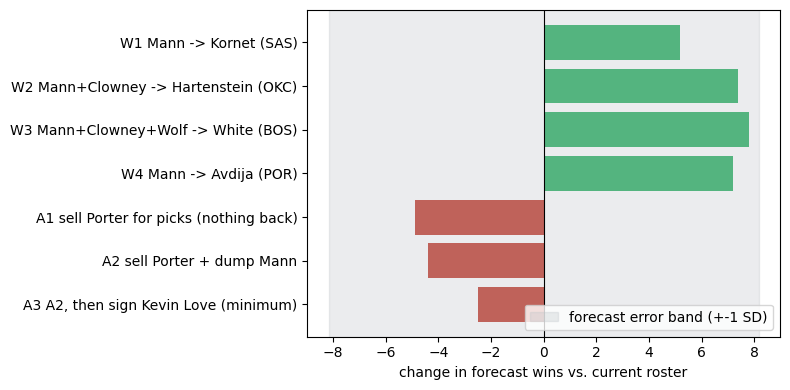


Teams (June payroll file) that could absorb Porter without sending salary back:
team_abbr
CHI     93.0
LAL    105.3


In [7]:
CAP, TAX, AP1, AP2 = 164.961, 200.428, 209.015, 221.686
NETS_PAYROLL = 160.325

c2 = con[con.salary_2026_27.notna()].copy()
c2["key"] = c2.player_name.map(norm)
c2["sal"] = c2.salary_2026_27 / 1e6
payroll = c2.groupby("team_abbr").sal.sum()
c_keys = list(c2.key)

def contract(name):
    k = norm(name)
    if k not in c_keys:
        m = difflib.get_close_matches(k, c_keys, n=1, cutoff=0.9)
        if not m:
            return None
        k = m[0]
    return c2[c2.key == k].iloc[0]

def max_in(out_m):
    if out_m <= 7.5:
        return 2 * out_m + 0.25
    if out_m <= 29:
        return out_m + 7.5
    return 1.25 * out_m + 0.25

def check(out, inn):
    o = [contract(n) for n in out]
    i = [contract(n) for n in inn]
    out_m = sum(x.sal for x in o if x is not None)
    in_m = sum(x.sal for x in i if x is not None)
    post = NETS_PAYROLL - out_m + in_m
    ok = ((post <= CAP) or (in_m <= max_in(out_m))) if inn else True
    tm = [x.team_abbr for x in i if x is not None]
    team = tm[0] if tm else "-"
    ptxt = "-"
    if team in payroll.index:
        pp = payroll[team]
        ppost = pp - in_m + out_m
        pok = (ppost <= CAP) or (out_m <= max_in(in_m))
        if ppost > AP1:
            pok = out_m <= in_m
        ptxt = "%s %.0f->%.0f %s" % (team, pp, ppost, "ok?" if pok else "NO?")
    return out_m, in_m, post, ok, ptxt

sc = [
 ("W1 Mann -> Kornet (SAS)",                 ["Terance Mann"], ["Luke Kornet"], [5]),
 ("W2 Mann+Clowney -> Hartenstein (OKC)",    ["Terance Mann", "Noah Clowney"], ["Isaiah Hartenstein"], [2]),
 ("W3 Mann+Clowney+Wolf -> White (BOS)",     ["Terance Mann", "Noah Clowney", "Danny Wolf"], ["Derrick White"], [2]),
 ("W4 Mann -> Avdija (POR)",                 ["Terance Mann"], ["Deni Avdija"], [2]),
 ("A1 sell Porter for picks (nothing back)", ["Michael Porter Jr."], [], []),
 ("A2 sell Porter + dump Mann",              ["Michael Porter Jr.", "Terance Mann"], [], []),
 ("A3 A2, then sign Kevin Love (minimum)",   ["Michael Porter Jr.", "Terance Mann"], [], []),
]
rows = []
for name, out, inn, slots in sc:
    order = change(BASE, out=out, add=inn, at=slots if inn else None)
    if name.startswith("A3"):
        order = change(order, add=["Kevin Love"], at=[5])
    _, w = forecast(order)
    out_m, in_m, post, ok, ptxt = check(out, inn)
    rows.append((name, round(w, 1), round(w - base_w, 1), round(out_m, 1), round(in_m, 1),
                 round(post, 1), "yes" if ok else "NO", ptxt))
R = pd.DataFrame(rows, columns=["scenario", "wins", "d_wins", "out_$M", "in_$M",
                                "Nets_payroll_after", "Nets_legal", "partner(file, approx)"])
print("Base case: %.1f wins (+-%.1f)\n" % (base_w, BAND))
print(R.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(R.scenario[::-1], R.d_wins[::-1],
        color=["#27ae60" if v > 0 else "#c0392b" for v in R.d_wins[::-1]])
ax.axvline(0, color="k", lw=0.8)
ax.axvspan(-BAND, BAND, color="#bdc3c7", alpha=0.3, label="forecast error band (+-1 SD)")
ax.set_xlabel("change in forecast wins vs. current roster")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

print("\nTeams (June payroll file) that could absorb Porter without sending salary back:")
room = payroll[(payroll + 40.8 <= CAP) & ~payroll.index.isin(["BRK", "BKN", "FA"])].sort_values()
print(room.round(1).to_string() if len(room) else "none")

**Reading it.**
- **W1, W3, W4 add 5-8 wins on paper; W2 is illegal by $0.1M.** (Incoming 28.5 vs a maximum of 28.4 on 20.9 outgoing; adding Wolf, as in W3, fixes it.) Most of the gain is a minutes effect: Mann (-3.06) leaves the rotation and the better player takes 22-30 minutes, pushing weaker players down. The price in picks and young players is not modelled, so these are an upper bound on what a trade is worth, not a recommendation.
- **Selling Porter costs about 4-5 wins** (A1, A2). Dumping Mann alongside him loses less because Mann was already below replacement. Adding Love recovers about 2 wins. Selling Porter for nothing back is only possible to a team with room under the cap; in the (June) file only Chicago and the Lakers show it, so in practice salary comes back.
- **With a +-8 error band, the 30-vs-34 difference between "asset" and "as is" is within noise.** The case for selling does not rest on the forecast; it rests on the picks and young players that come back, which this notebook does not value (see 6b for why a high own pick is not part of that case).

## 6b. What selling Porter really buys: the draft picture

It is tempting to say: sell Porter Jr., win about 29-31 games, land a top-5 pick in the 2027 draft. **That does not work for Brooklyn's own 2027 pick**, for this reason:

- Houston holds *swap rights* on Brooklyn's 2027 first-round pick (from the 2021 James Harden trade). Houston takes the better of its own and Brooklyn's 2027 pick; Brooklyn gets the other one. A current mock draft (nbadraftroom.com, updated 20 Oct 2026) already lists the No. 2 pick as "Rockets, via Nets".
- So a *worse* Brooklyn record mostly improves the pick Houston can swap into; Brooklyn ends up with the less favourable of the two, which is likely a mid-to-late pick unless Houston is also bad. Brooklyn's own 2026-27 wins therefore barely change Brooklyn's 2027 pick.
- What losing can still affect: Brooklyn's own 2028 pick and the Phoenix swap options for 2028 (the Nets can swap into Phoenix's pick). Other reported Brooklyn picks include Phoenix's 2029 first, the 2027 firsts of Philadelphia (top-8 protected) and New York, the Knicks' 2028 first and Denver's 2032 first (unprotected). These pick details come from sources dated 2024-2025 and were **not re-verified**.

**Consequence for the asset scenario.** The value of selling Porter is what comes back in the trade (picks or young players from the buyer), not a higher own 2027 pick. Wins in 2026-27 still have other value (player development, culture, revenue, the 2028 pick), so "lose on purpose" is not free either.

**If Brooklyn ends up with a 2027 lottery pick anyway** (for example through a pick in the Porter package), the following players are at the top of one public mock draft (nbadraftroom.com, 20 Oct 2026; one site's view, a year before the draft, not our evaluation):

| # | Player | Pos | School / team | Class |
|---|---|---|---|---|
| 1 | Jordan Smith Jr. | SG | Arkansas | Fr |
| 2 | Tyran Stokes | SF | Kansas | Fr |
| 3 | Stefan Joksimovic | SF | Slovenia | Int. |
| 4 | Hugo Yimga Moukouri | SF | France | Int. |
| 5 | Bruce Branch | SF | BYU | Fr |
| 6 | Motiejus Krivas | C | Arizona | Sr |
| 7 | Caleb Holt | SG | Arizona | Fr |
| 8 | Luigi Suigo | C | Villanova | Fr |
| 9 | Quentin Coleman | SG | Illinois | Fr |
| 10 | Thomas Haugh | PF | Florida | Sr |

**Positional fit (a hypothesis, not a scouting report).** Brooklyn's problems were shooting efficiency and turnovers, and the roster already has five young guards (Brown, Demin, Traore, Saraf, Powell). By that logic a wing or forward who can shoot is a better fit than another guard. A real recommendation would need college statistics and film, which this notebook does not have.


## 7. What to take from this, and what not to

- **The roster is bad on paper and projects to roughly the low 30s**, with a range of about 26-42 wins. Prediction markets say mid-20s.
- **Playing time is the biggest lever.** Rotation order is worth about as much as the best trade scenario here.
- **Free agency cannot help.** The best available player is worth under two wins and the model likely overrates the veterans.
- **Porter Jr. is the central decision.** He is the best player on the team and on an expiring deal; selling him costs about 4-5 wins but returns assets.
- **Losing does not buy Brooklyn a 2027 lottery pick.** Houston holds swap rights on it (section 6b), so the case for selling rests on what comes back in the trade.

**Limitations**
- BPM comes from box scores. It misses defence that does not show up there and is noisy for small minutes.
- One-season inputs (last year's BPM) ignore age curves, injuries and development.
- Forecast error about +-8 wins (1 SD) from the backtest; Brooklyn itself was over-predicted last year.
- Rotation minutes are assumed, not predicted; no injuries.
- Contract data are from 18 June 2026; Brooklyn's 2026-27 salaries are from public reports (some unconfirmed, e.g. how much of Porter's salary is guaranteed). Partner payroll checks are approximate.
- Trade-matching tiers are from a 2024-25 summary and were not re-checked for 2026-27.
- Pick ownership and protections (section 6b) come from sources dated 2024-2025 and were not re-verified; the mock draft is one site's view.
- Hypothetical trades only; no pick valuation, no partner willingness, no "second-order" effects (chemistry, spacing, defence).